In [1]:
# !nrnivmodl mod

# Configs

In [2]:
import numpy as np
import os
from matplotlib import pyplot as plt

%matplotlib inline

In [3]:
from netpyne import sim, specs
import pickle

cfg = specs.SimConfig()

cfg.duration = 120 ## Duration of the sim, in ms
cfg.dt = 0.025
cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321}
cfg.hParams = {'celsius': 34, 'v_init': -72.5}
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

allpops = ['HL23PYR']

cfg.recordCells = allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'},
                    'V_axon_0': {'sec':'axon_0', 'loc':0.5, 'var':'v'},
                    'V_axon_1': {'sec':'axon_1', 'loc':0.5, 'var':'v'},
                    'V_axon_2': {'sec':'axon_2', 'loc':0.5, 'var':'v'},
                    'V_dend_5': {'sec':'dend_5', 'loc':0.5, 'var':'v'},
                    'V_apic_57': {'sec':'apic_57', 'loc':0.5, 'var':'v'},
                    }


## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = 0.025

cfg.simLabel = 'L23_Net'
cfg.saveFolder = '.'
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simData' , 'simConfig', 'netParams', 'netParams']
cfg.backupCfgFile = None 		##
cfg.gatherOnlySimData = False	##
cfg.saveCellSecs = True			##
cfg.saveCellConns = True		##

cfg.analysis['plotTraces'] = {'include': allpops, 'figSize': (12, 4), 'timeRange': [0,cfg.duration], 'saveFig': False, 'overlay': True, 'oneFigPer': 'cell'}  # Plot recorded traces for this list of cells

In [4]:
#------------------------------------------------------------------------------
#
# NETWORK PARAMETERS
#
#------------------------------------------------------------------------------

netParams = specs.NetParams()   # object of class NetParams to store the network parameters

cellModels = ['HH_full']
Epops = ['HL23PYR']

#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------

MODELS_DIR = 'models'

# =============================================================================
# SECTION 1: Cell Parameters (cellParams)
#
# Each cell type has a standalone wrapper HOC template (HL23XXX_Cell.hoc) that:
#   1. Loads the cell-specific SWC morphology (path hardcoded in the template)
#   2. Runs geom_nseg()
#   3. Applies the correct axon policy (delete_axon or delete_axon_BPO)
#   4. Calls biophys() — all channel insertions are done inside init()
#
# A single importCellParams call per cell type is sufficient.
# importCellParams instantiates the template, then scans h.allsec() to capture
# all section geometry + mechanisms into the cellParams secs dict.
# =============================================================================


for cell_name in allpops:
    wrapper_hoc   = os.path.join(MODELS_DIR, f'{cell_name}_Cell.hoc')
    template_name = cell_name + '_Cell'

    cellRule = netParams.importCellParams(
        label          = cell_name,
        fileName       = wrapper_hoc,
        cellName       = template_name,
        importSynMechs = False,
        somaAtOrigin   = True,
    )

    # Tag the rule so popParams can reference it by condition
    netParams.cellParams[cell_name]['conds'] = {
        'cellType':  cell_name,
        'cellModel': 'HH_full',
    }

    # Define named section lists for connParams compartment targeting.
    # These mirror the SWC section types used in the original HOC model.
    secs = netParams.cellParams[cell_name]['secs']
    apic_secs  = sorted([s for s in secs if s.startswith('apic')])
    dend_secs  = sorted([s for s in secs if s.startswith('dend')])
    soma_secs  = sorted([s for s in secs if s.startswith('soma')])
    axon_secs  = sorted([s for s in secs if s.startswith('axon') or s.startswith('myelin')])

    netParams.cellParams[cell_name]['secLists'] = {
        'all':     soma_secs + dend_secs + apic_secs + axon_secs,
        'spiny':   dend_secs + apic_secs,
        'somatic': soma_secs,
        'basal':   dend_secs,
        'apical':  apic_secs,
        'axonal':  axon_secs,
        # 'spiny' used internally; SYN_POS=0 is split into two rules
    }


In [5]:

cfg.invertedYCoord = False
cfg.ROTATE_Y = True
cfg.Change_axon_names = True

# ----------------------------------------------------------------------------------------------------------------------- #
# Rotate to z as vertical
# ----------------------------------------------------------------------------------------------------------------------- #
if cfg.ROTATE_Y:

    rotate_x = {}
    rotate_y = {}
    rotate_z = {}
    rotate_x['HL23PYR'], rotate_x['HL23SST'], rotate_x['HL23PV'], rotate_x['HL23VIP'] = 1.57, 1.77, 1.26, -1.57
    rotate_y['HL23PYR'], rotate_y['HL23SST'], rotate_y['HL23PV'], rotate_y['HL23VIP'] = 2.62, 2.77, 2.57, 3.57
    rotate_z['HL23PYR'], rotate_z['HL23SST'], rotate_z['HL23PV'], rotate_z['HL23VIP'] = 0.0, 0.0, 0.0, 0.0


    for cellName in netParams.cellParams.keys():

        cellType = netParams.cellParams[cellName]['conds']['cellType']

        x = rotate_x[cellType]
        y = rotate_y[cellType]
        z = rotate_z[cellType]

        for sectName in netParams.cellParams[cellName]['secs'].keys():

            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            theta = -x
            rotation_x = np.array([[1, 0, 0],
                                        [0, np.cos(theta), -np.sin(theta)],
                                        [0, np.sin(theta), np.cos(theta)]])
            
            # print(cellName,sectName,len(sectParams_new))
            # print(sectParams_new)       
            
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_x)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams


            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            phi = -y
            rotation_y = np.array([[np.cos(phi), 0, np.sin(phi)],
                                        [0, 1, 0],
                                        [-np.sin(phi), 0, np.cos(phi)]])
            
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_y)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams


            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            gamma = -z
            rotation_z = np.array([[np.cos(gamma), -np.sin(gamma), 0],
                                        [np.sin(gamma), np.cos(gamma), 0],
                                        [0, 0, 1]])
        
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_z)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams

    # ----------------------------------------------------------------------------------------------------------------------- #
    # Rotate to Y as vertical axis
    # ----------------------------------------------------------------------------------------------------------------------- #

    rotate_x = {}
    rotate_y = {}
    rotate_z = {}
    rotate_x['HL23PYR'], rotate_x['HL23SST'], rotate_x['HL23PV'], rotate_x['HL23VIP'] = -1.5708, -1.5708, -1.5708, -1.5708
    rotate_y['HL23PYR'], rotate_y['HL23SST'], rotate_y['HL23PV'], rotate_y['HL23VIP'] = 0.0, 0.0, 0.0, 0.0
    rotate_z['HL23PYR'], rotate_z['HL23SST'], rotate_z['HL23PV'], rotate_z['HL23VIP'] = 0.0, 0.0, 0.0, 0.0


    for cellName in netParams.cellParams.keys():

        cellType = netParams.cellParams[cellName]['conds']['cellType']

        x = rotate_x[cellType]
        y = rotate_y[cellType]
        z = rotate_z[cellType]

        for sectName in netParams.cellParams[cellName]['secs'].keys():

            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            theta = -x
            rotation_x = np.array([[1, 0, 0],
                                        [0, np.cos(theta), -np.sin(theta)],
                                        [0, np.sin(theta), np.cos(theta)]])
            
            # print(cellName,sectName,len(sectParams_new))
            # print(sectParams_new)       
            
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_x)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams


            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            phi = -y
            rotation_y = np.array([[np.cos(phi), 0, np.sin(phi)],
                                        [0, 1, 0],
                                        [-np.sin(phi), 0, np.cos(phi)]])
            
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_y)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams


            sectParams_new = netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d']
            sectParams = []

            gamma = -z
            rotation_z = np.array([[np.cos(gamma), -np.sin(gamma), 0],
                                        [np.sin(gamma), np.cos(gamma), 0],
                                        [0, 0, 1]])
        
            for i in range(len(sectParams_new)):
                x3d, y3d, z3d, L3d = sectParams_new[i]
                rel_pos = x3d, y3d, z3d

                # print(rel_pos)        
                rel_pos = np.dot(rel_pos, rotation_z)
                # print(rel_pos)
                pt3d = (rel_pos[0],rel_pos[1] , rel_pos[2], L3d)
                sectParams.append(pt3d)

            netParams.cellParams[cellName]['secs'][sectName]['geom']['pt3d'] = sectParams


if cfg.Change_axon_names:
    #------------------------------------------------------------------------------
    # Change axon names
    #------------------------------------------------------------------------------
    # print and rename
    for cellName in netParams.cellParams.keys():
            
        if 'myelin_0' in netParams.cellParams[cellName]['secs'].keys():

            netParams.renameCellParamsSec(label=cellName, oldSec='myelin_0', newSec='axon_2')      
                
            for secname2 in netParams.cellParams[cellName]['secLists'].keys():
                if 'myelin_0' in netParams.cellParams[cellName]['secLists'][secname2]:
                    # print('old ->',cellName,secname2,netParams.cellParams[cellName]['secLists'][secname2][-1])
                    netParams.cellParams[cellName]['secLists'][secname2][-1] = 'axon_2'    
                    # print('new ->',cellName,secname2,netParams.cellParams[cellName]['secLists'][secname2][-1])



# Population parameters

In [6]:
#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------
cellName = 'HL23PYR'
netParams.popParams[cellName] = {'cellType': cellName, 'cellModel': 'HH_full', 'numCells': 1,
            'xRange': [0, 1],
            'zRange': [0, 1],
            'yRange': [-1500.0,-1450.0]}

#------------------------------------------------------------------------------
# Current inputs (SinClamp)
#------------------------------------------------------------------------------
# Tutorial reference:
# http://doc.netpyne.org/tutorial.html#tutorial-8-running-batch-simulations

# bias_Stim = -0.05   # stim in nA -> [-0.05, 0.0, 0.05]
# pkamp_Stim = 0.25    # peak in nA -> [0.0, 0.05, 0.1, 0.15, 0.1, 0.2, 0.25],
# freq_Stim = 5.0     # freq senoidal in Hz -> [1.O, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0],

# netParams.stimSourceParams['sineStim'] = {'type': 'SinClamp', 'delay': 500.0, 'dur': 4000.0, 'pkamp': pkamp_Stim, 'freq': freq_Stim, 'phase': 0.0, 'bias': bias_Stim}
# netParams.stimTargetParams['sineStim_sPY'] = {
#     'source': 'sineStim',
#     'conds': {'pop': 'HL23PYR'},
#     'sec': 'soma_0',
#     'loc': 0.5
# }

# #------------------------------------------------------------------------------
# #  extracellular mechs
# #------------------------------------------------------------------------------
for celltyp in netParams.cellParams.keys():
    label = []
    for secname in netParams.cellParams[celltyp]['secs'].keys():
        netParams.cellParams[celltyp]['secs'][secname]['mechs']['extracellular'] = {}

#------------------------------------------------------------------------
# External Stimulation
#------------------------------------------------------------------------------
from stimulation import make_extracellular_stimuli

cfg.addExternalStimulation = True

# The parameters of the extracellular point current source
cfg.acs_params = {'position': [0.0, 0.0, 0.0],  # um # y = [pia, bone]
              'amp': 500.,  # uA,
              'stimstart': 50.0,  # ms
              'stimend': cfg.duration,  # ms
              'frequency': 2.0,  # Hz
              'sigma': 0.57  # decay constant S/m
              }

In [7]:
# netParams.cellParams[celltyp]['secs']['axon_2']['geom']['L'] = 100.0
# netParams.cellParams[celltyp]['secs']['axon_2']['geom']['nseg'] = 3
del netParams.cellParams[celltyp]['secs']['axon_2']

# Run

In [8]:
sim.initialize(
    simConfig = cfg,
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations


for metype in sim.net.cells:
    # print('cell ->', metype.tags['cellType'], metype.tags['cellModel'], metype.tags['pop'])
    if metype.tags['cellType'] == 'HL23PYR':
        metype.secs['axon_0']['hObj'](0.1).diam = 2.875
        metype.secs['axon_0']['hObj'](0.3).diam = 2.625
        metype.secs['axon_0']['hObj'](0.5).diam = 2.375
        metype.secs['axon_0']['hObj'](0.7).diam = 2.125
        metype.secs['axon_0']['hObj'](0.9).diam = 1.875

        metype.secs['axon_1']['hObj'](0.0714286).diam = 1.6964285714285714
        metype.secs['axon_1']['hObj'](0.214286).diam = 1.5892857142857142
        metype.secs['axon_1']['hObj'](0.357143).diam = 1.4821428571428572
        metype.secs['axon_1']['hObj'](0.5).diam = 1.375
        metype.secs['axon_1']['hObj'](0.642857).diam = 1.2678571428571428
        metype.secs['axon_1']['hObj'](0.785714).diam = 1.1607142857142856
        metype.secs['axon_1']['hObj'](0.928571).diam = 1.0535714285714286

    if metype.tags['cellType'] == 'HL23SST':
        metype.secs['axon_0']['hObj'](0.1).diam = 2.875
        metype.secs['axon_0']['hObj'](0.3).diam = 2.625
        metype.secs['axon_0']['hObj'](0.5).diam = 2.375
        metype.secs['axon_0']['hObj'](0.7).diam = 2.125
        metype.secs['axon_0']['hObj'](0.9).diam = 1.875

        metype.secs['axon_1']['hObj'](0.0714286).diam = 1.6964285714285714
        metype.secs['axon_1']['hObj'](0.214286).diam = 1.5892857142857142
        metype.secs['axon_1']['hObj'](0.357143).diam = 1.4821428571428572
        metype.secs['axon_1']['hObj'](0.5).diam = 1.375
        metype.secs['axon_1']['hObj'](0.642857).diam = 1.2678571428571428
        metype.secs['axon_1']['hObj'](0.785714).diam = 1.1607142857142856
        metype.secs['axon_1']['hObj'](0.928571).diam = 1.0535714285714286

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.net.defineCellShapes()
if cfg.addExternalStimulation:
        #Add extracellular stim
        for c,metype in enumerate(sim.net.cells):
            if metype.tags['cellModel'] == 'HH_full':
                secList = [secs for secs in metype.secs.keys() if "pt3d" in metype.secs[secs]['geom']]
                print("\n", metype.tags, "nsec =",len(secList))
                print(secList)
                v_cell_ext, cell = make_extracellular_stimuli(cfg.acs_params, metype, secList)

sim.runSim()                      			# run parallel Neuron simulation

if cfg.addExternalStimulation:
        for c,metype in enumerate(sim.net.cells):
            if metype.tags['cellModel'] == 'HH_full':
                # print("\n", metype.tags)
                metype.t_ext.clear()
                metype.v_ext.clear()                   			# run parallel Neuron simulation

sim.gatherData();                  			# gather spiking data and cell info from each node
# sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
# sim.analysis.plotData()         			# plot spike raster etc
# sim.analysis.plotShape()


Start time:  2026-05-21 20:13:41.597235




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.01 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
  Number of stims on node 0: 0 
  Done; cell stims creation time = 0.00 s.
Recording 5 traces of 5 types on node 0

 {'cellType': 'HL23PYR', 'cellModel': 'HH_full', 'pop': 'HL23PYR', 'xnorm': 0.0011551505114987609, 'ynorm': -14.61761718240622, 'znorm': 0.009230938465513537, 'x': 0.11551505114987609, 'y': -1461.761718240622, 'z': 0.9230938465513536} nsec = 91
['soma_0', 'dend_0', 'dend_1', 'dend_2', 'dend_3', 'dend_4', 'dend_5', 'dend_6', 'dend_7', 'dend_8', 'dend_9', 'dend_10', 'dend_11', 'dend_12', 'dend_13', 'dend_14', 'dend_15', 'dend_16', 'dend_17', 'dend_18', 'dend_19', 'dend_20', 'dend_21', 'dend_22', 'dend_23', 'dend_24', 'dend_25', 'dend_26', 'dend_27', 'dend_28', 'dend_29', 'apic_0', 'apic_1', 'apic_2', 'apic_3', 'apic_4', 'apic_5', 'apic_6', 'apic_7', 'apic_8', 'apic_9', 'apic_10', 'apic_11', 'apic_12', 'apic_1

  Done; run time = 0.33 s; real-time ratio: 0.36.

Gathering data...
  Done; gather time = 0.01 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 1 (8.33 Hz)
  Simulated time: 0.1 s; 1 workers
  Run time: 0.33 s
   HL23PYR : 8.333 Hz


# Plot figures

Plotting recorded cell traces ... cell


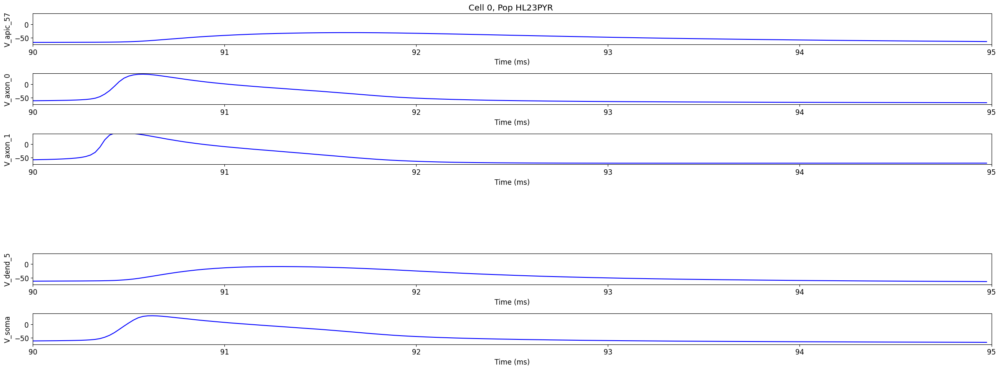

In [12]:
sim.analysis.plotTraces(overlay=False, timeRange=[90,cfg.duration-25], oneFigPer='cell', ylim= [-75,40], figSize=(24,9), fontSize=12, saveFig=False, axis=True);

Plotting 3D cell shape ...


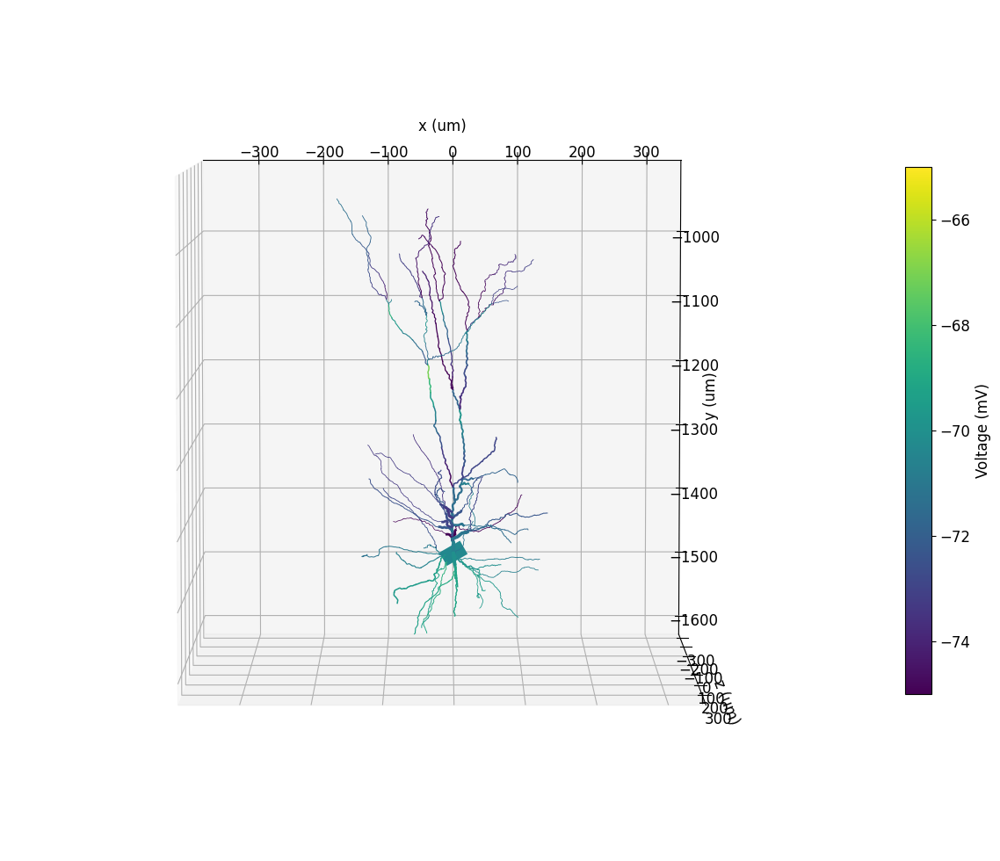

In [10]:
sim.analysis.plotShape(includePre=[cellName], includePost=[cellName], includeAxon=True, showSyns=False, showElectrodes=False,
                                cvar= 'voltage', dist=0.6, elev=95, azim=-90, 
                                axisLabels=True, synStyle='o', 
                                clim= [-75, -65], showFig=False, synSize=2, saveFig=False, figSize=(12,12));

# Video


Start time:  2026-05-21 20:13:42.504404




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.01 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
  Number of stims on node 0: 0 
  Done; cell stims creation time = 0.00 s.
Recording 5 traces of 5 types on node 0

 {'cellType': 'HL23PYR', 'cellModel': 'HH_full', 'pop': 'HL23PYR', 'xnorm': 0.0011551505114987609, 'ynorm': -14.61761718240622, 'znorm': 0.009230938465513537, 'x': 0.11551505114987609, 'y': -1461.761718240622, 'z': 0.9230938465513536} nsec = 91
0.0s

Running with interval func using NEURON for 120.0 ms...
0.9999999999999984
1.999999999999995
3.000000000000009
4.000000000000023
5.000000000000037
6.0000000000000515
7.000000000000066
8.00000000000008
9.000000000000023
9.999999999999966
10.99999999999991
11.999999999999853
12.999999999999796
13.999999999999739
14.999999999999682
15.999999999999625
16.99999999999957
17.999999999999513
18.999999999999456
19.9999999999994
20.999999999999343
21.999999999999286
22.9

40.00000000000053
41.00000000000076
42.00000000000099
43.000000000001215
44.00000000000144
45.00000000000167
46.0000000000019
47.000000000002125
48.00000000000235
49.00000000000258
50.00000000000281

Gathering data...
  Done; gather time = 0.01 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 0 (0.00 Hz)
  Simulated time: 0.1 s; 1 workers
  Run time: 1779405222.62 s
   HL23PYR : 0.000 Hz
Plotting 3D cell shape ...
51.000000000003034

Gathering data...
  Done; gather time = 0.01 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 0 (0.00 Hz)
  Simulated time: 0.1 s; 1 workers
  Run time: 1779405222.62 s
   HL23PYR : 0.000 Hz
Plotting 3D cell shape ...
52.00000000000326

Gathering data...
  Done; gather time = 0.01 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 0 (0.00 Hz)
  Simulated time: 0.1 s; 1 workers
  Run time: 1779405222.62 s
   HL23PYR : 0.000 Hz
Plotting 3D cell shape ...
53.00000000000349

Gathering data...
  Do

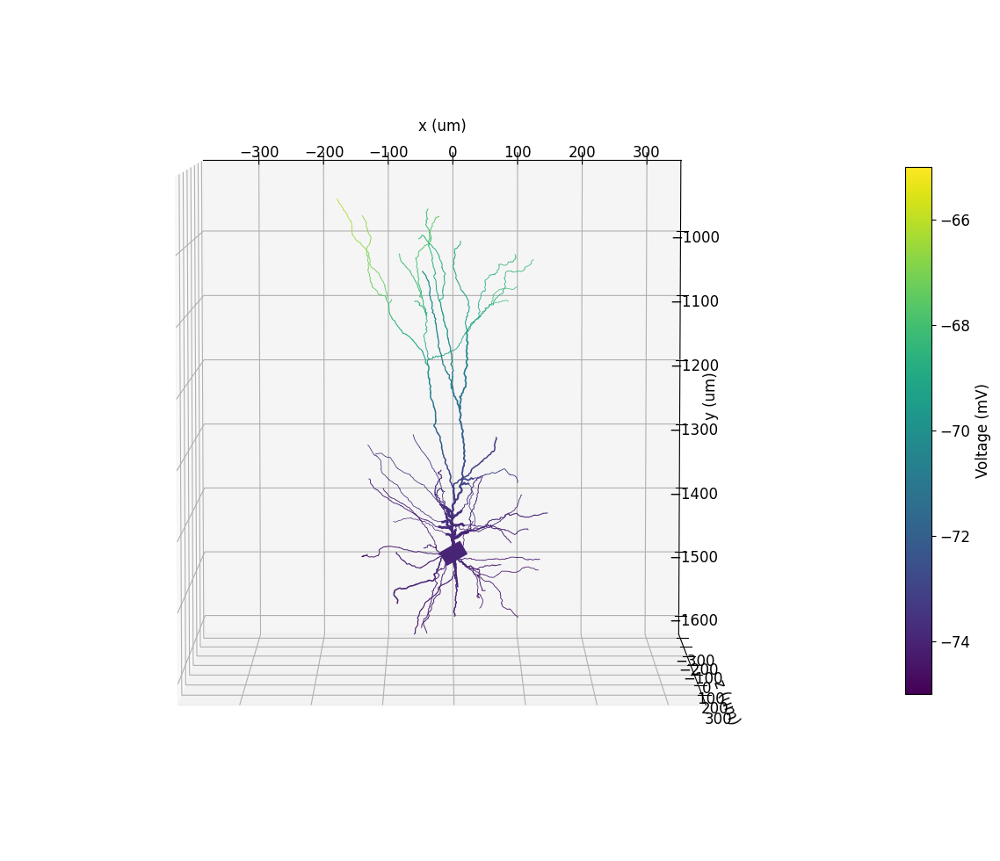

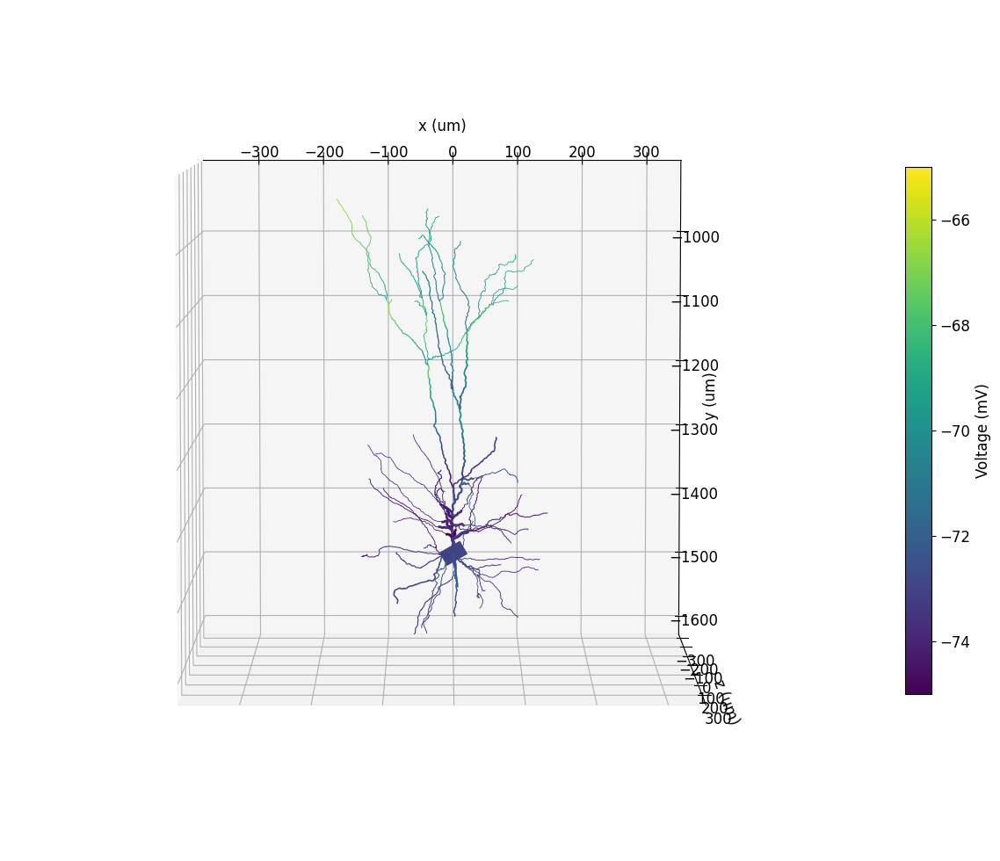

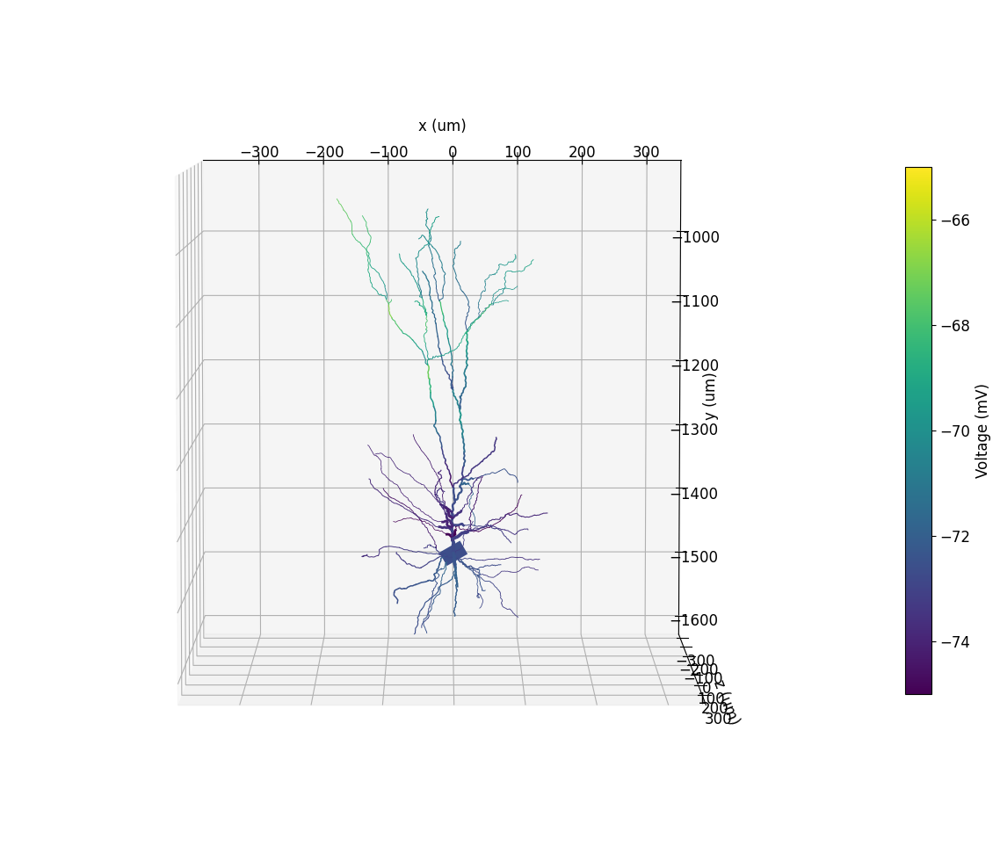

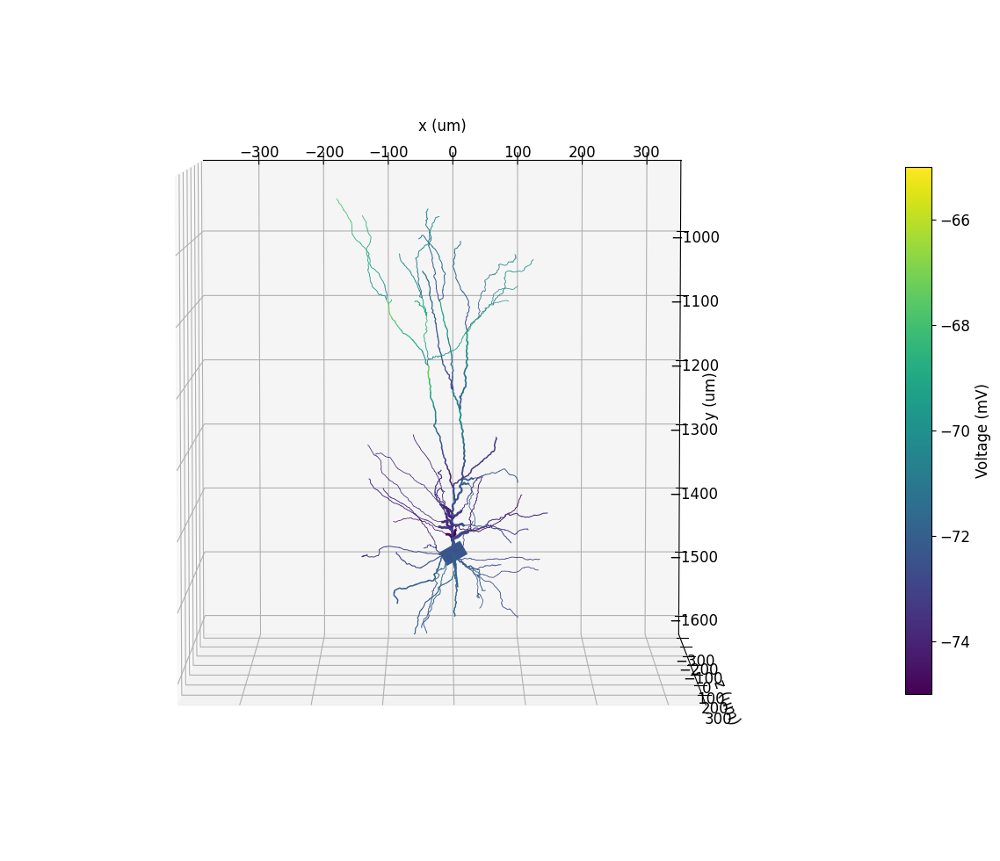

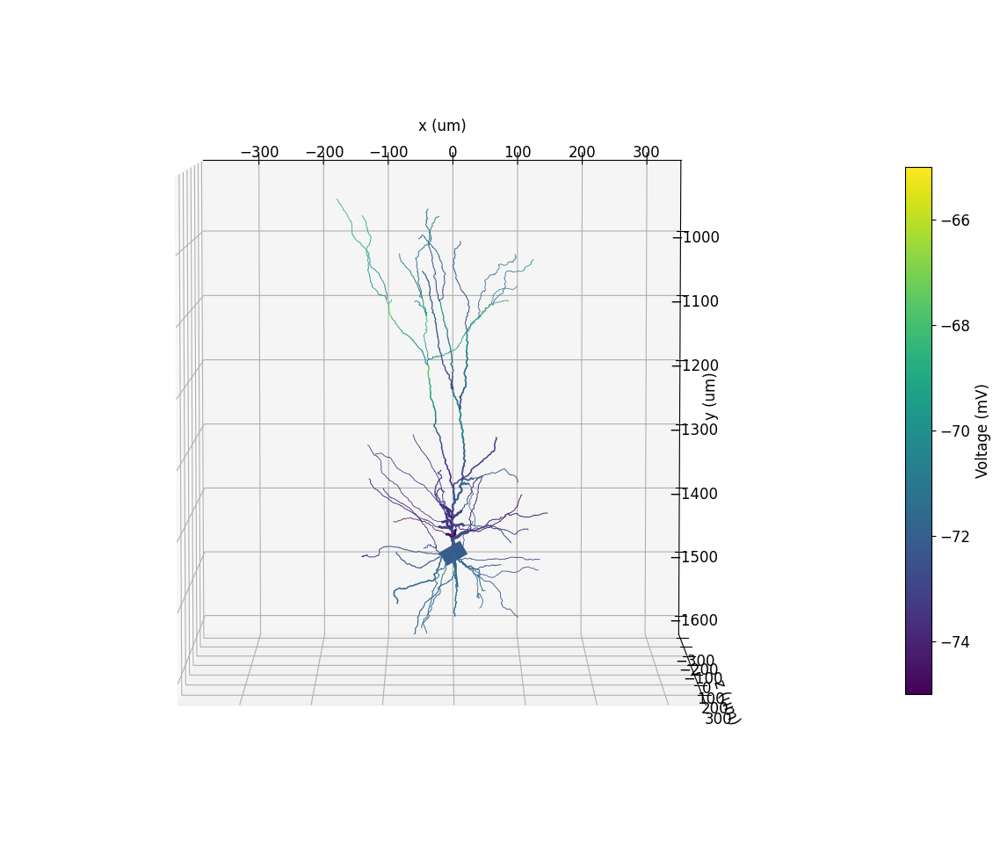

...

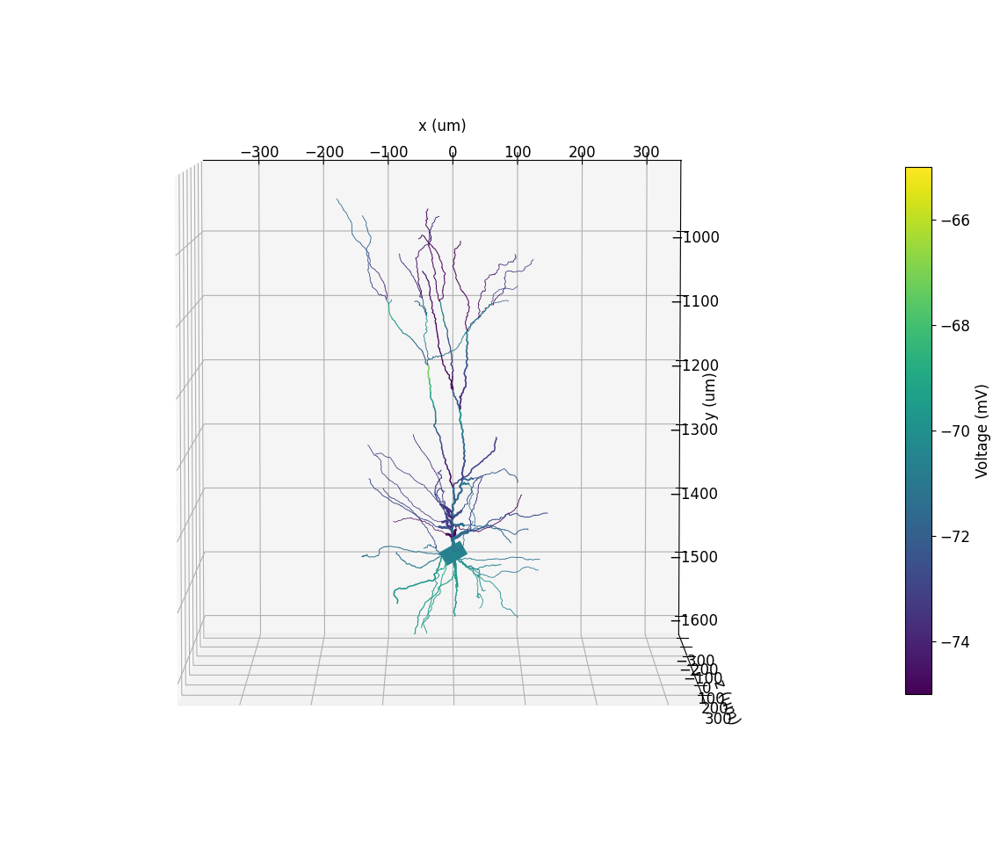

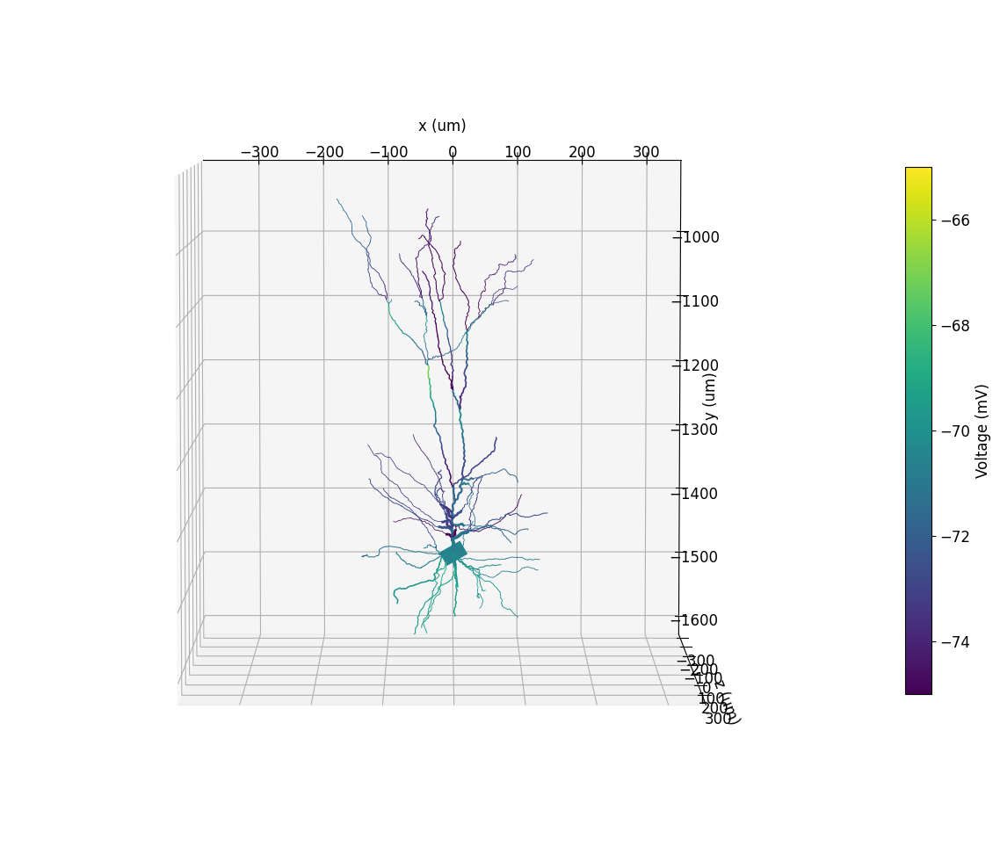

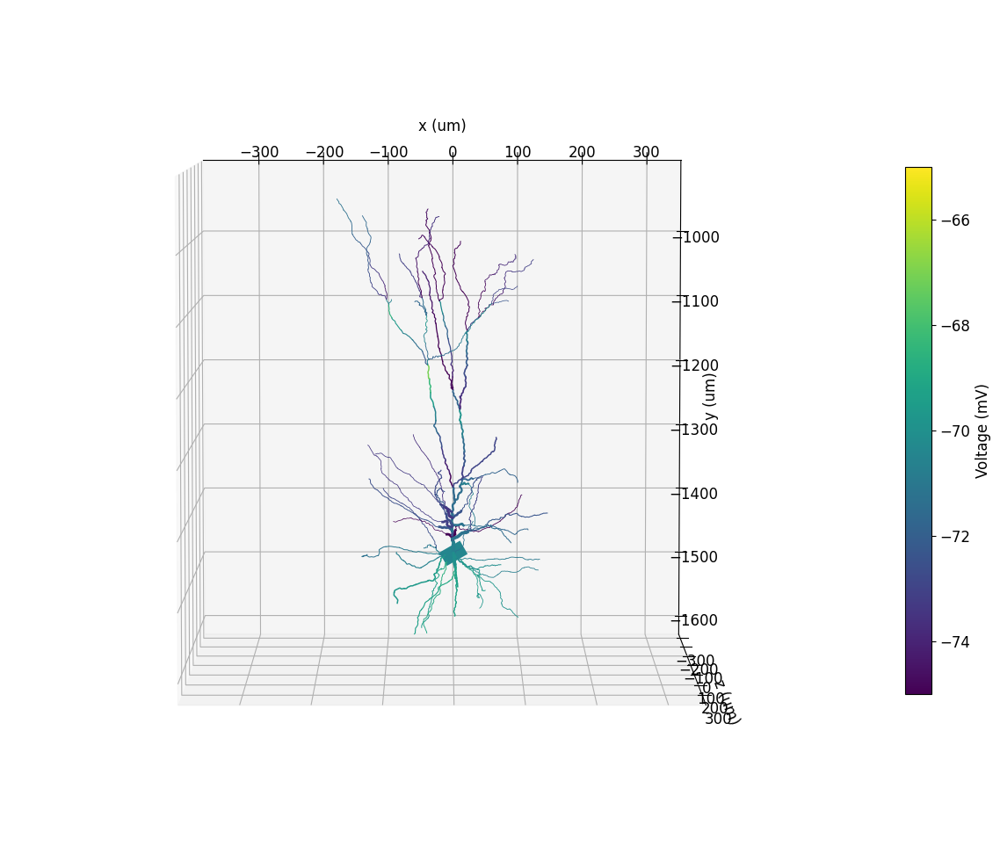

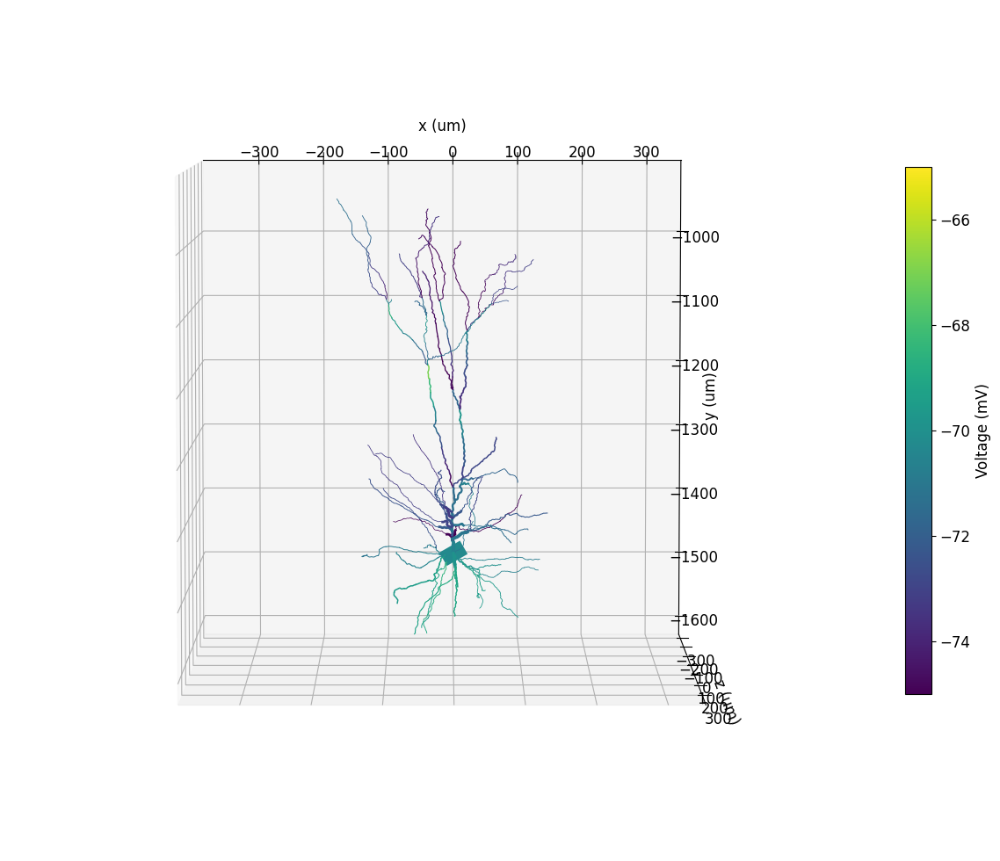

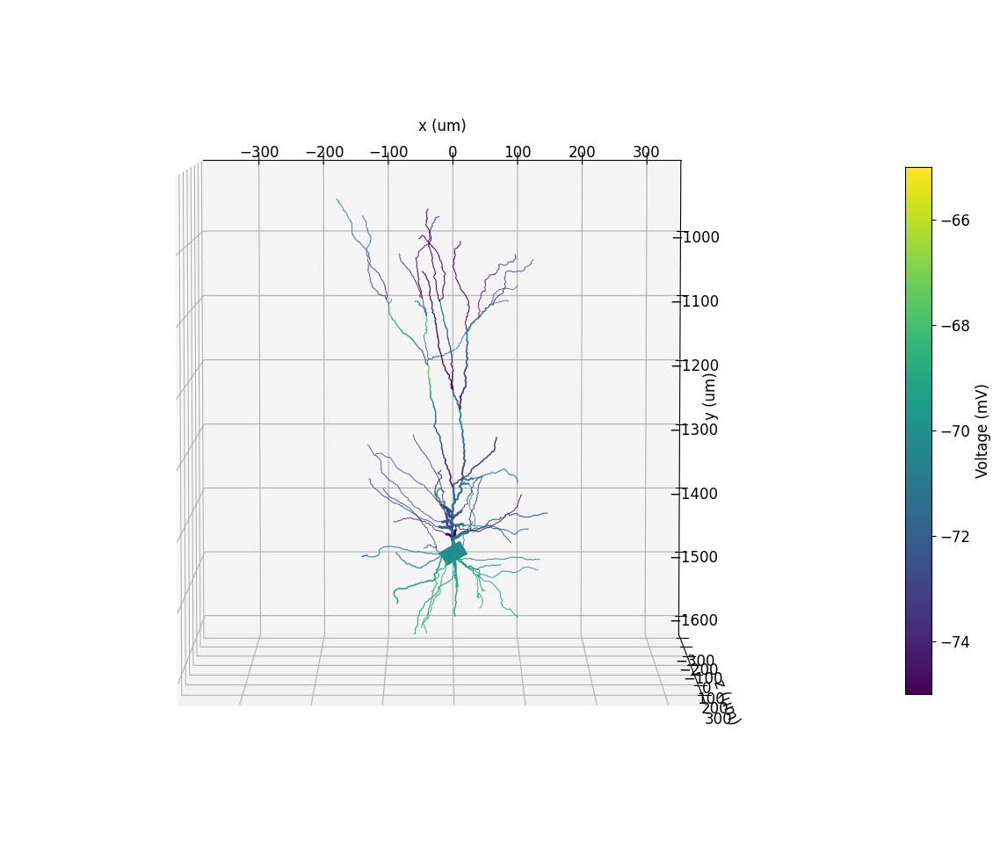

In [11]:
def modifyMechsFunc(simTime):   

    t = simTime
    print(t)

    if t >= cfg.acs_params['stimstart'] and t <= cfg.acs_params['stimend'] + cfg.dt: 
        
        sim.gatherData()
        sim.analysis.plotShape(includePre=[cellName], includePost=[cellName], includeAxon=True, showSyns=False, showElectrodes=False,
                                cvar= 'voltage', dist=0.6, elev=95, azim=-90, 
                                axisLabels=True, synStyle='o', 
                                clim= [-75, -65], showFig=False, synSize=2, saveFig='t%.3fms.png' % float(1000*t), figSize=(12,12));

# -----------------------------------------------------------
# Main code

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  # create network object and set cfg and net params

sim.pc.timeout(300)                          # set nrn_timeout threshold to X sec (max time allowed without increasing simulation time, t; 0 = turn off)
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations
sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)

sim.net.defineCellShapes()
if cfg.addExternalStimulation:
        #Add extracellular stim
        for c,metype in enumerate(sim.net.cells):
            if metype.tags['cellModel'] == 'HH_full':
                secList = [secs for secs in metype.secs.keys() if "pt3d" in metype.secs[secs]['geom']]
                print("\n", metype.tags, "nsec =",len(secList))
                # print(secList)
                v_cell_ext, cell = make_extracellular_stimuli(cfg.acs_params, metype, secList)

# Simulation option 2: interval function to modify mechanism params
sim.runSimWithIntervalFunc(40*cfg.dt, modifyMechsFunc)       # run parallel Neuron simulation (calling func to modify mechs)

if cfg.addExternalStimulation:
        for c,metype in enumerate(sim.net.cells):
            if metype.tags['cellModel'] == 'HH_full':
                # print("\n", metype.tags)
                metype.t_ext.clear()
                metype.v_ext.clear()

##------------------------------------------------ VIDEO ----------------------------------------------------------- ##
import subprocess, glob, os

# Build sorted file list and create MP4 from simulation PNG frames
png_files = sorted(glob.glob('t*.png'), key=lambda f: float(f[1:-7]))  # strip leading 't' and trailing '.png'

list_file = 'frames_list.txt'
with open(list_file, 'w') as f:
    for p in png_files:
        f.write(f"file '{os.path.abspath(p)}'\n")

output_video = 'simulation_t51000_t100000ms.mp4'

cmd = [
    'ffmpeg', '-y',
    '-r', '10',                        # 10 fps  ->  5 s total for 50 frames
    '-f', 'concat', '-safe', '0',
    '-i', list_file,
    '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2',
    '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-crf', '18',
    output_video
]

result = subprocess.run(cmd, capture_output=True, text=True)
os.remove(list_file)

if result.returncode != 0:
    print(result.stderr[-2000:])
else:
    print(f'Video saved: {output_video}  ({len(png_files)} frames @ 5 fps)')

try:
    removepngout = [os.remove(file) for file in png_files]
except:
    print("No png files")